# 04 - Findings & charts (Michele)
Input: `../data_clean/reviews_laundry_features.csv` (output of notebook 02). Run from inside `findings/`.

Output: slide-ready charts in `findings/figures/`. Models use the same specification as notebook 03 (main model) so the numbers match the Method section.

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from statsmodels.stats.proportion import proportions_ztest
from pathlib import Path

DATA = "../data_clean/reviews_laundry_features.csv"
FIG = Path("figures"); FIG.mkdir(exist_ok=True)

d = pd.read_csv(DATA)
A = [c for c in d.columns if c.startswith("a_")]
m = d.dropna(subset=["low"]).copy()          # 3-star reviews excluded, as in 03
m["verified"] = m.verified_purchase.astype(int)
lowr = m[m.low == 1]

# Plain names for slides
# Plain names and colours match the Tutorial II deck
NAME = {
    "a_support": "Customer support", "a_repair_service": "Repair / technician",
    "a_reliability": "Breakdown / reliability", "a_return_refund": "Return / refund",
    "a_drying_clothes": "Drying / clothes care", "a_value": "Price / value",
    "a_cleaning": "Cleaning / smell", "a_noise": "Noise / vibration",
    "a_delivery_install": "Delivery / install", "a_design_usability": "Design / usability",
}
SERVICE = {"a_support", "a_repair_service", "a_return_refund"}
PRODUCT = {"a_reliability"}

BLUE, ORANGE, GREY, DARK = "#2B78D6", "#E8743B", "#A3A29D", "#333333"
def group_colour(a):
    return BLUE if a in SERVICE else ORANGE if a in PRODUCT else GREY
plt.rcParams.update({
    "figure.figsize": (11, 6), "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "font.size": 13, "axes.titlesize": 16, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelsize": 13, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": DARK, "text.color": DARK, "axes.labelcolor": DARK,
    "xtick.color": DARK, "ytick.color": DARK, "legend.frameon": False,
})

def note(fig, text):
    """Small source/sample line under the chart."""
    fig.text(0.01, -0.02, text, fontsize=10, color="#666666", ha="left", va="top")

print(f"all reviews: {len(d):,} | model sample (1-2 vs 4-5 stars): {len(m):,} | low-rated: {len(lowr):,}")

all reviews: 3,938 | model sample (1-2 vs 4-5 stars): 3,737 | low-rated: 2,447


## Models (same formula as notebook 03)

In [2]:
f = "low ~ " + " + ".join(A) + " + C(brand, Treatment('LG')) + verified + C(year)"
main = smf.logit(f, data=m).fit(disp=0, cov_type="cluster", cov_kwds={"groups": pd.factorize(m.product_id)[0]})

lg = m[m.is_lg == 1]
lg_fit = smf.logit("low ~ " + " + ".join(A) + " + verified + C(year)", data=lg).fit(disp=0, cov_type="cluster", cov_kwds={"groups": pd.factorize(lg.product_id)[0]})

def or_table(fit):
    ci = fit.conf_int().loc[A]
    return pd.DataFrame({"OR": np.exp(fit.params[A]), "lo": np.exp(ci[0]), "hi": np.exp(ci[1]),
                         "p": fit.pvalues[A]})

or_main, or_lg = or_table(main), or_table(lg_fit)
or_main.round(3).sort_values("OR", ascending=False)

,OR,lo,hi,p
a_support,4.949,3.031,8.081,0.000
a_return_refund,3.728,2.152,6.457,0.000
a_reliability,3.382,2.480,4.613,0.000
a_repair_service,3.333,2.674,4.154,0.000
a_drying_clothes,1.322,0.997,1.752,0.052
a_value,1.133,0.907,1.415,0.271
a_cleaning,0.974,0.764,1.242,0.832
a_noise,0.697,0.554,0.876,0.002
a_delivery_install,0.571,0.228,1.431,0.232
a_design_usability,0.555,0.449,0.686,0.000


## Chart 1 - Share of 1-2 star reviews by brand

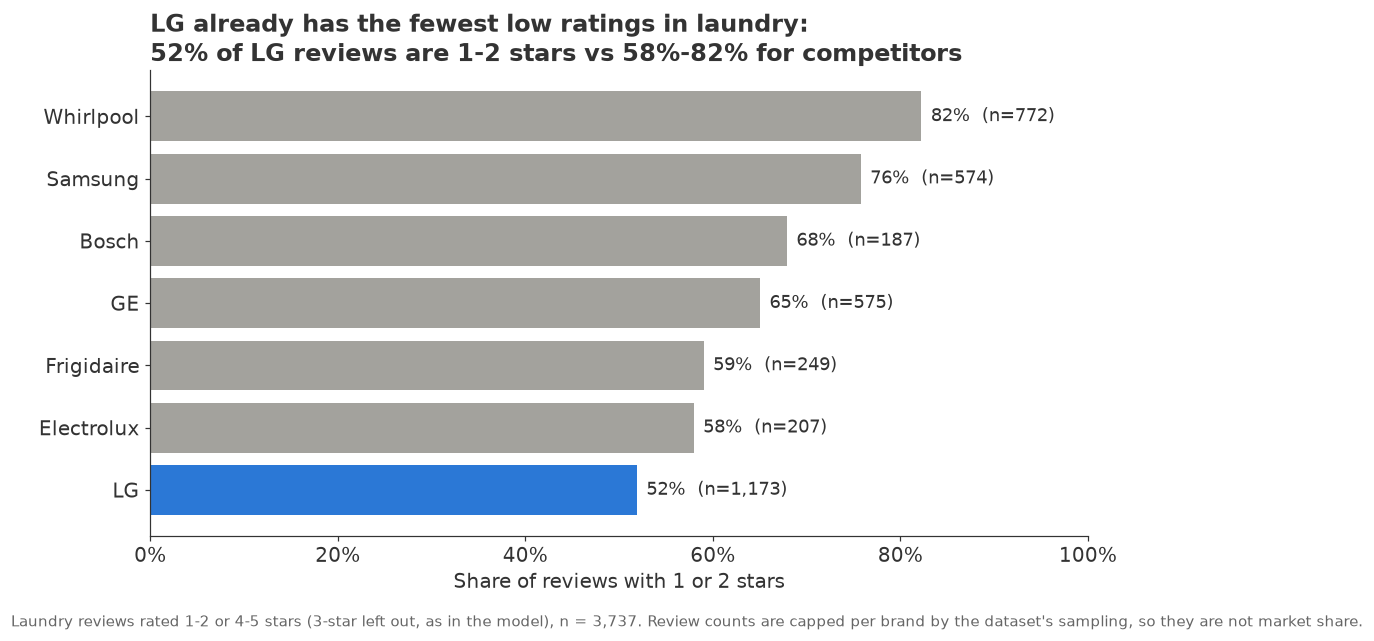

,mean,size
brand,,
LG,0.519,1173
Electrolux,0.580,207
Frigidaire,0.590,249
GE,0.650,575
Bosch,0.679,187
Samsung,0.758,574
Whirlpool,0.823,772


In [3]:
b = m.groupby("brand").low.agg(["mean", "size"]).sort_values("mean")   # same outcome as the model: 1-2 vs 4-5 stars
fig, ax = plt.subplots(figsize=(11, 5.5))
cols = [BLUE if x == "LG" else GREY for x in b.index]
ax.barh(b.index, b["mean"], color=cols)
for i, (share, n) in enumerate(zip(b["mean"], b["size"])):
    ax.text(share + 0.01, i, f"{share:.0%}  (n={n:,})", va="center", fontsize=12)
ax.set_xlim(0, 1); ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
ax.set_xlabel("Share of reviews with 1 or 2 stars")
co = b.drop("LG")["mean"]
ax.set_title(f"LG already has the fewest low ratings in laundry:\n"
             f"{b.loc['LG','mean']:.0%} of LG reviews are 1-2 stars vs {co.min():.0%}-{co.max():.0%} for competitors")
note(fig, f"Laundry reviews rated 1-2 or 4-5 stars (3-star left out, as in the model), n = {len(m):,}. Review counts are capped per brand by the dataset's sampling, so they are not market share.")
fig.savefig(FIG / "chart1_low_share_by_brand.png"); plt.show()
b.round(3)

## Chart 2 - What drives a low rating (odds ratios, all brands)

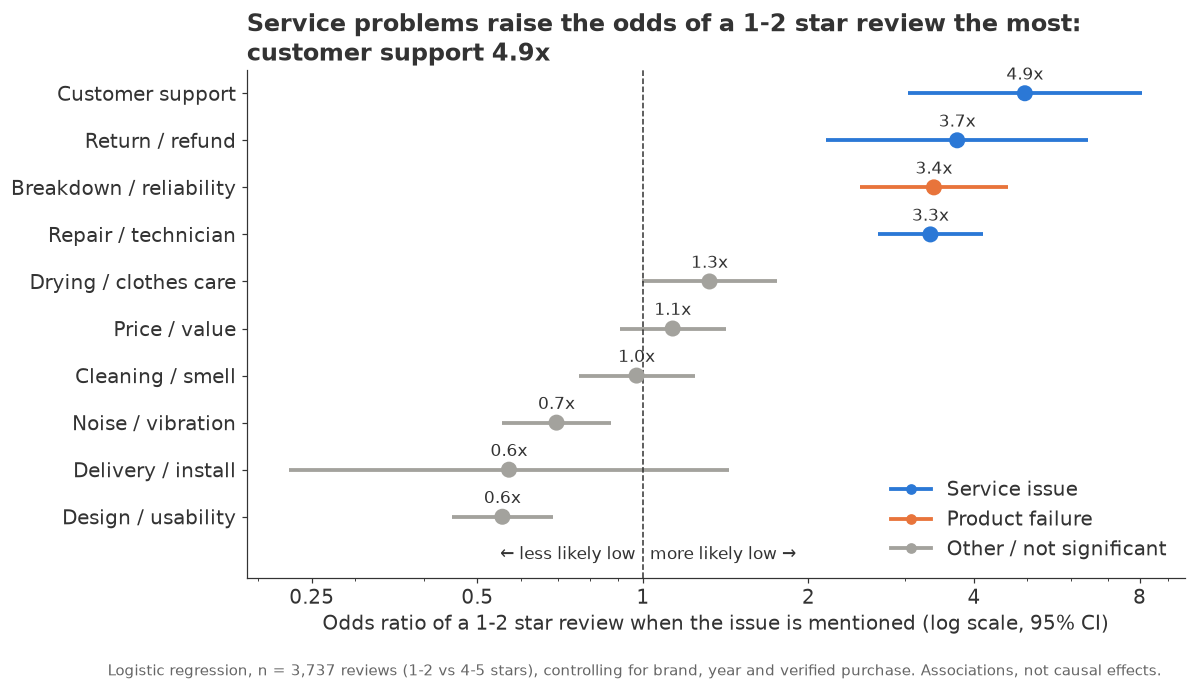

In [4]:
t = or_main.sort_values("OR")
harm = (t.p < 0.05) & (t.OR > 1)
col = [group_colour(a) if h else GREY for a, h in zip(t.index, harm)]
fig, ax = plt.subplots(figsize=(11, 6))
y = np.arange(len(t))
ax.hlines(y, t.lo, t.hi, color=col, lw=2.5)
ax.scatter(t.OR, y, color=col, s=90, zorder=3)
for yi, o in enumerate(t.OR):
    ax.annotate(f"{o:.1f}x", (o, yi), xytext=(0, 9), textcoords="offset points", ha="center", fontsize=11)
ax.axvline(1, color=DARK, ls="--", lw=1)
ax.set_xscale("log"); ax.set_xticks([0.25, 0.5, 1, 2, 4, 8]); ax.set_xticklabels(["0.25", "0.5", "1", "2", "4", "8"])
ax.xaxis.set_minor_formatter(plt.NullFormatter())
ax.set_yticks(y); ax.set_yticklabels([NAME[i] for i in t.index])
ax.set_xlabel("Odds ratio of a 1-2 star review when the issue is mentioned (log scale, 95% CI)")
ax.set_title("Service problems raise the odds of a 1-2 star review the most:\n"
             f"customer support {or_main.loc['a_support','OR']:.1f}x")
ax.text(1.03, -0.9, "more likely low →", fontsize=11, color=DARK)
ax.text(0.97, -0.9, "← less likely low", fontsize=11, color=DARK, ha="right")
from matplotlib.lines import Line2D
ax.legend(handles=[Line2D([], [], color=c, marker="o", lw=2.5, label=l) for c, l in
                   [(BLUE, "Service issue"), (ORANGE, "Product failure"), (GREY, "Other / not significant")]], loc="lower right")
ax.set_ylim(-1.3, len(t) - 0.5)
note(fig, f"Logistic regression, n = {int(main.nobs):,} reviews (1-2 vs 4-5 stars), controlling for brand, year and verified purchase. Associations, not causal effects.")
fig.savefig(FIG / "chart2_odds_ratios.png"); plt.show()

## Chart 3 - LG vs competitors: what low-rated reviews talk about

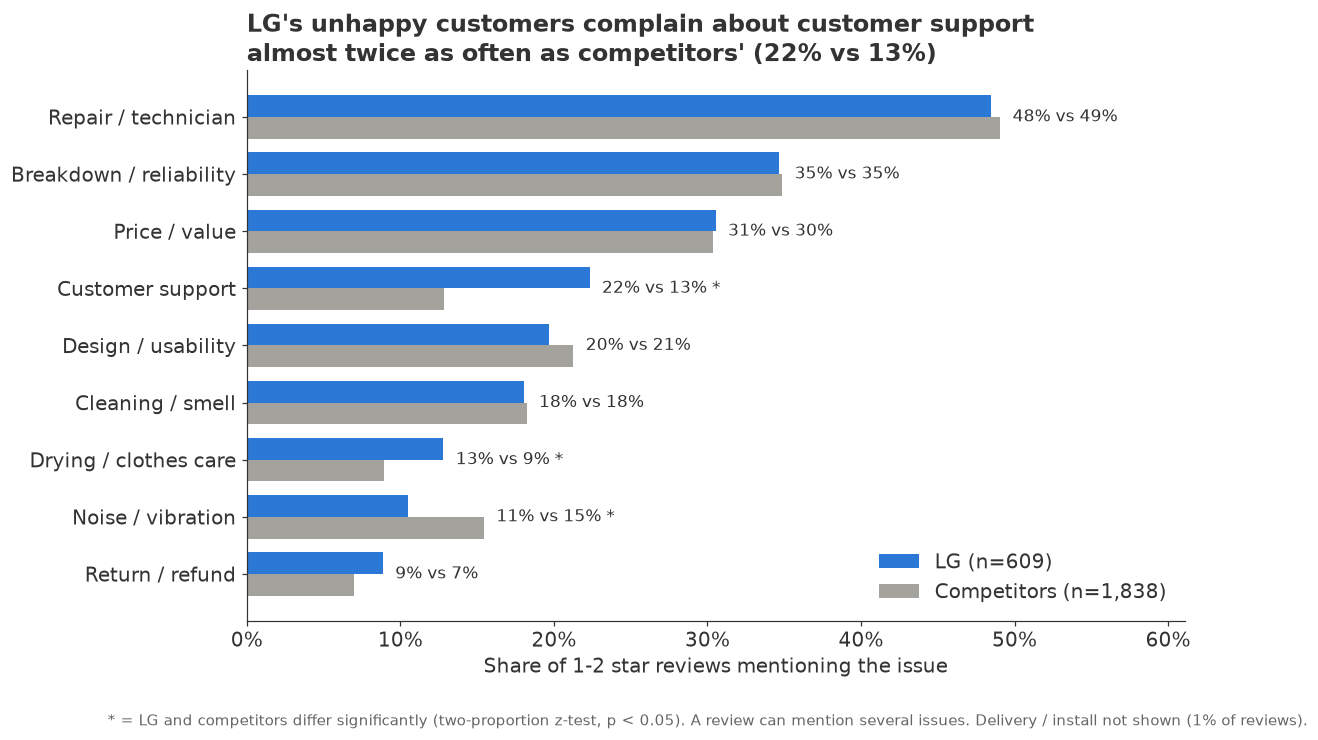

,LG,Competitors,gap_pts,p
a_support,0.223,0.128,9.492,0.000
a_drying_clothes,0.128,0.089,3.885,0.005
a_return_refund,0.089,0.070,1.903,0.121
a_value,0.305,0.304,0.183,0.932
a_cleaning,0.181,0.182,-0.164,0.928
a_reliability,0.346,0.349,-0.228,0.919
a_repair_service,0.484,0.491,-0.635,0.786
a_design_usability,0.197,0.213,-1.569,0.409
a_noise,0.105,0.155,-4.943,0.002


In [5]:
g = lowr.groupby("is_lg")[A]
cmp_ = pd.DataFrame({"LG": g.mean().loc[1], "Competitors": g.mean().loc[0]})
n_lg, n_co = int((lowr.is_lg == 1).sum()), int((lowr.is_lg == 0).sum())
cmp_["gap_pts"] = (cmp_.LG - cmp_.Competitors) * 100
cmp_["p"] = [proportions_ztest([lowr.loc[lowr.is_lg == 1, a].sum(), lowr.loc[lowr.is_lg == 0, a].sum()], [n_lg, n_co])[1] for a in A]
cmp_ = cmp_.drop("a_delivery_install", errors="ignore").sort_values("LG")   # deck: delivery not shown (1% of reviews)

fig, ax = plt.subplots(figsize=(11, 6.5))
y = np.arange(len(cmp_)); h = 0.38
ax.barh(y + h / 2, cmp_.LG, h, color=BLUE, label=f"LG (n={n_lg:,})")
ax.barh(y - h / 2, cmp_.Competitors, h, color=GREY, label=f"Competitors (n={n_co:,})")
for yi, (a, r) in enumerate(cmp_.iterrows()):
    star = " *" if r.p < 0.05 else ""
    ax.text(max(r.LG, r.Competitors) + 0.008, yi, f"{r.LG:.0%} vs {r.Competitors:.0%}{star}", va="center", fontsize=11)
ax.set_yticks(y); ax.set_yticklabels([NAME[i] for i in cmp_.index])
ax.set_xlim(0, cmp_[["LG", "Competitors"]].max().max() + 0.12)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
ax.set_xlabel("Share of 1-2 star reviews mentioning the issue")
s = cmp_.loc["a_support"]
ax.set_title(f"LG's unhappy customers complain about customer support\nalmost twice as often as competitors' ({s.LG:.0%} vs {s.Competitors:.0%})")
ax.legend(loc="lower right")
note(fig, "* = LG and competitors differ significantly (two-proportion z-test, p < 0.05). A review can mention several issues. Delivery / install not shown (1% of reviews).")
fig.savefig(FIG / "chart3_lg_vs_competitors.png"); plt.show()
cmp_.round(3).sort_values("gap_pts", ascending=False)

## Chart 4 - Priority matrix for LG
x = how often the issue appears in LG's 1-2 star reviews. y = how much it raises the odds of a low rating, from the **LG-only** model (notebook 03, section 2). Top-right = frequent and harmful = fix first. Hollow markers = not significant at 5%.

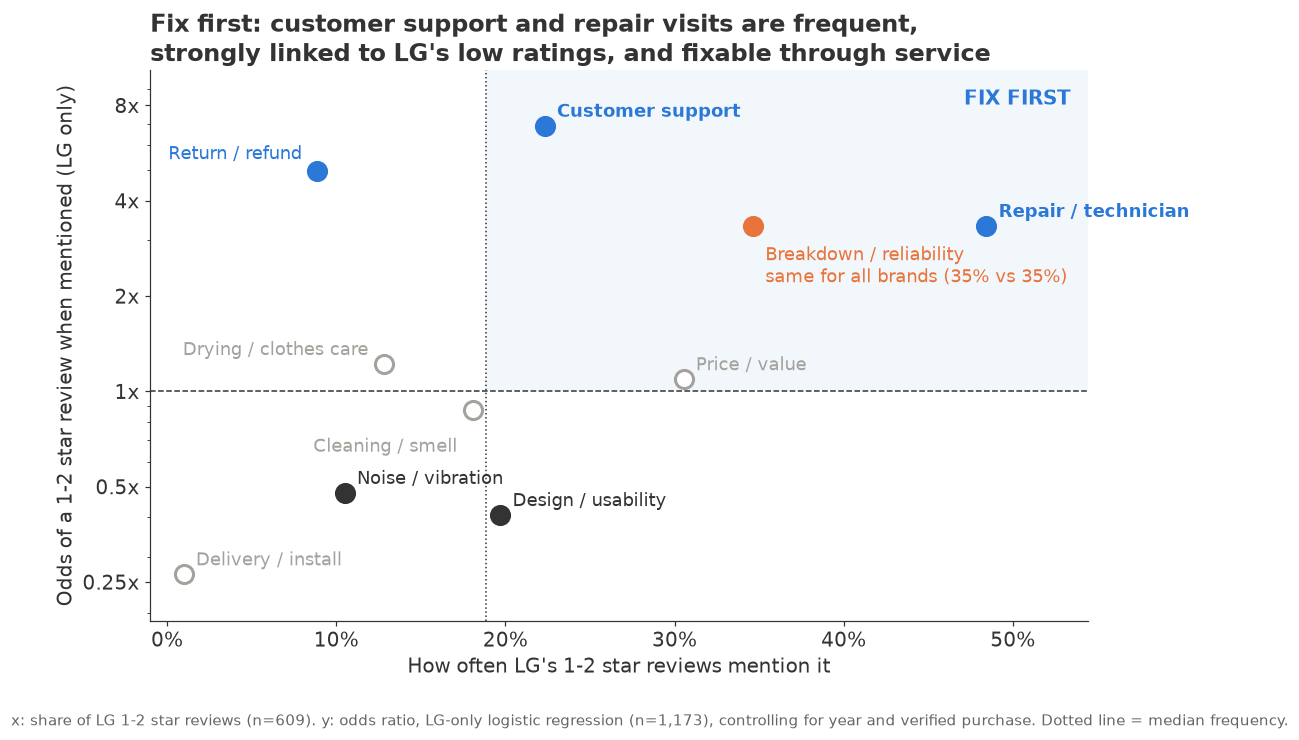

,freq,OR,p
a_support,0.223,6.888,0.000
a_return_refund,0.089,4.954,0.000
a_reliability,0.346,3.329,0.000
a_repair_service,0.484,3.325,0.000
a_drying_clothes,0.128,1.218,0.348
a_value,0.305,1.091,0.661
a_cleaning,0.181,0.872,0.480
a_noise,0.105,0.477,0.001
a_design_usability,0.197,0.406,0.000
a_delivery_install,0.010,0.264,0.072


In [6]:
pri = pd.DataFrame({"freq": lowr[lowr.is_lg == 1][A].mean(), "OR": or_lg.OR, "p": or_lg.p})
x_cut = pri.freq.median()
OFFSET = {"a_cleaning": (-10, -18, "right"), "a_drying_clothes": (-10, 6, "right"), "a_return_refund": (-10, 8, "right"),
          "a_reliability": (8, -12, "left")}  # avoid label collisions
fig, ax = plt.subplots(figsize=(11, 6.5))
ax.set_yscale("log")
ax.axhline(1, color=DARK, ls="--", lw=1); ax.axvline(x_cut, color=DARK, ls=":", lw=1)
for a, r in pri.iterrows():
    top = (r.freq >= x_cut) and (r.OR > 1) and (r.p < 0.05)
    c = group_colour(a) if (r.OR > 1 and r.p < 0.05) else (DARK if r.p < 0.05 else GREY)
    ax.scatter(r.freq, r.OR, s=140, color=c if r.p < 0.05 else "white", edgecolor=c, lw=2, zorder=3)
    dx, dy, ha = OFFSET.get(a, (8, 6, "left"))
    label = NAME[a]
    if a in PRODUCT:  # deck: same rate for every brand, a category problem, not an LG one
        label += "\nsame for all brands ({:.0%} vs {:.0%})".format(r.freq, cmp_.loc[a, "Competitors"])
    ax.annotate(label, (r.freq, r.OR), xytext=(dx, dy), textcoords="offset points", fontsize=12, ha=ha,
                va="top" if dy < 0 else "baseline", color=c, fontweight="bold" if (top and a in SERVICE) else "normal")
lim = pri.OR.max() * 1.5
ax.set_ylim(pri.OR.min() / 1.4, lim)
ax.fill_between([x_cut, pri.freq.max() + 0.06], 1, lim, color=BLUE, alpha=0.06, lw=0)
ax.yaxis.set_minor_formatter(plt.NullFormatter())
ax.set_yticks([0.25, 0.5, 1, 2, 4, 8]); ax.set_yticklabels(["0.25x", "0.5x", "1x", "2x", "4x", "8x"])
ax.set_xlim(-0.01, pri.freq.max() + 0.06)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
ax.text(pri.freq.max() + 0.05, lim / 1.15, "FIX FIRST", ha="right", va="top", fontsize=13, fontweight="bold", color=BLUE)
ax.set_xlabel("How often LG's 1-2 star reviews mention it")
ax.set_ylabel("Odds of a 1-2 star review when mentioned (LG only)")
ax.set_title("Fix first: customer support and repair visits are frequent,\nstrongly linked to LG's low ratings, and fixable through service")
note(fig, f"x: share of LG 1-2 star reviews (n={n_lg:,}). y: odds ratio, LG-only logistic regression (n={int(lg_fit.nobs):,}), controlling for year and verified purchase. Dotted line = median frequency.")
fig.savefig(FIG / "chart4_priority_matrix.png"); plt.show()
pri.round(3).sort_values("OR", ascending=False)

## Chart 5 - Replication on refrigerators
Same pipeline, `CATEGORY = "refrigerator_freezer"`. The cleaning steps (notebook 01) and the keyword tags (notebook 02) are **read from those notebooks and run as written**, so any later change to them carries over here. Nothing is written to `data_clean/`, and 01-03 are not modified.
Two technical changes, both because the model cannot be estimated otherwise: tags matching fewer than 10 fridge reviews (drying clothes: 2) are left out, and year enters as a linear trend (only one 2007 review), as Angelo did in the verified-only check.

In [7]:
import json
def nb_cell(nb, marker):
    """Source of the code cell in a teammate's notebook that contains `marker`."""
    cells = json.load(open(nb, encoding="utf8"))["cells"]
    return next("".join(c["source"]) for c in cells if c["cell_type"] == "code" and marker in "".join(c["source"]))

ns = {"pd": pd, "np": np, "CATEGORY": "refrigerator_freezer",
      "df": pd.read_csv("../data_raw/appliance_brand_reviews.csv", parse_dates=["review_date"])}
exec(nb_cell("../01_clean_explore.ipynb", "d = df[df.product_category == CATEGORY]"), ns)   # build + clean text
exec(nb_cell("../01_clean_explore.ipynb", "RV000685"), ns)                               # exclusions + low definition
ns["d"]["text_l"] = ns["d"].text.str.lower()
exec(nb_cell("../02_text_features.ipynb", "ATTR = {"), ns)                                # keyword tags
fd = ns["d"]

fm = fd.dropna(subset=["low"]).copy()
fm["verified"] = fm.verified_purchase.astype(int)
A_fr = [a for a in A if fm[a].sum() >= 10]   # a tag in <10 reviews cannot be estimated
dropped = sorted(set(A) - set(A_fr))
# Year as a linear trend, as in notebook 03's verified-only check: fridges have a single 2007 review,
# which makes C(year) unestimable (perfect separation). With C(year) the odds ratios are almost identical.
fr_fit = smf.logit("low ~ " + " + ".join(A_fr) + " + C(brand, Treatment('LG')) + verified + year", data=fm).fit(disp=0, cov_type="cluster", cov_kwds={"groups": pd.factorize(fm.product_id)[0]})
ci = fr_fit.conf_int().loc[A_fr]
or_fr = pd.DataFrame({"OR": np.exp(fr_fit.params[A_fr]), "lo": np.exp(ci[0]), "hi": np.exp(ci[1]), "p": fr_fit.pvalues[A_fr]})
print(f"refrigerator reviews: {len(fd):,} | model sample: {int(fr_fit.nobs):,} | converged: {fr_fit.mle_retvals['converged']} | tags left out: {dropped}")
or_fr.round(3).sort_values("OR", ascending=False)

suspicious titles: 0
(4686, 20) | 3-star share: 0.065


refrigerator reviews: 4,686 | model sample: 4,381 | converged: True | tags left out: ['a_drying_clothes']


,OR,lo,hi,p
a_return_refund,6.987,4.165,11.721,0.000
a_support,4.866,3.123,7.581,0.000
a_reliability,4.702,3.697,5.980,0.000
a_repair_service,3.590,2.633,4.894,0.000
a_delivery_install,2.881,1.599,5.191,0.000
a_value,1.094,0.884,1.352,0.409
a_noise,0.919,0.680,1.242,0.584
a_cleaning,0.541,0.316,0.927,0.025
a_design_usability,0.430,0.344,0.538,0.000


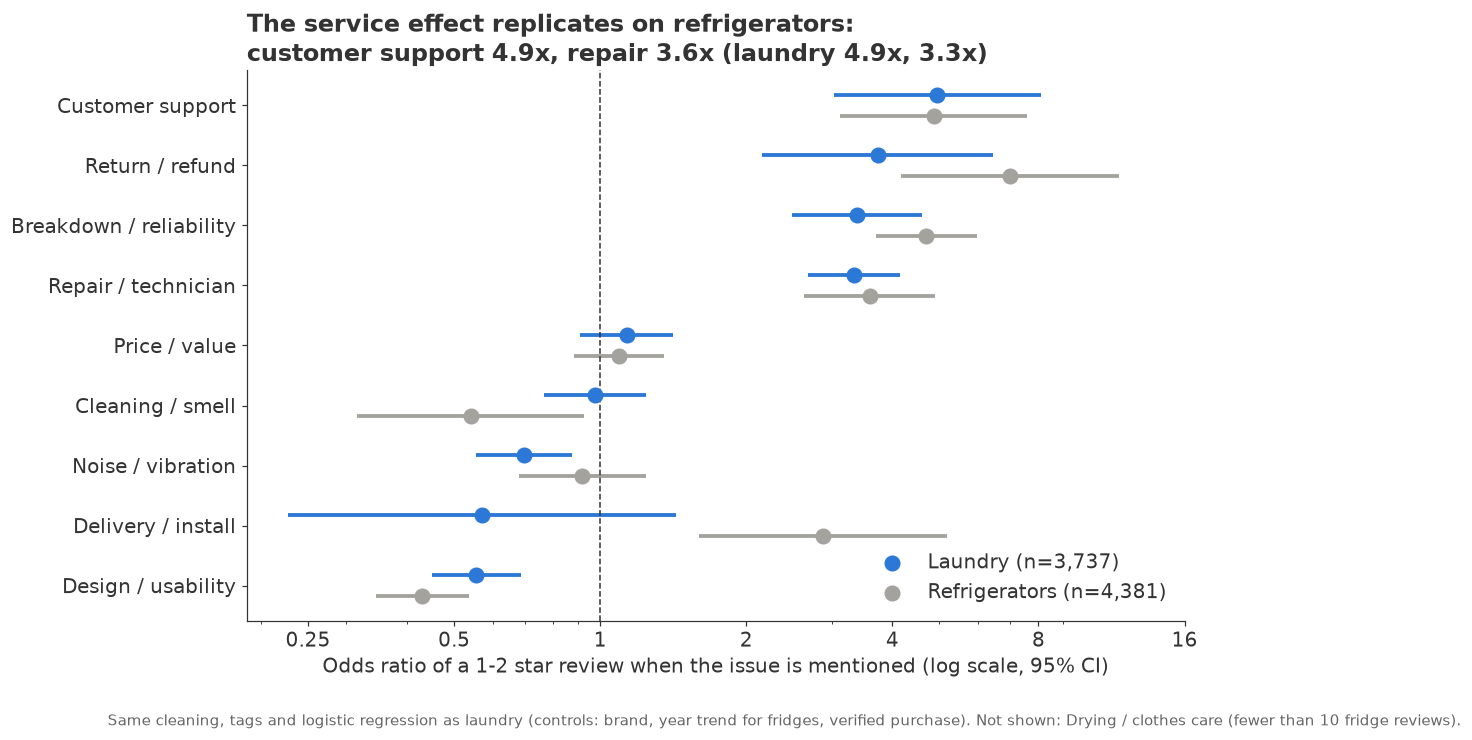

,lau,lau_lo,lau_hi,fr,fr_lo,fr_hi
a_design_usability,0.56,0.45,0.69,0.43,0.34,0.54
a_delivery_install,0.57,0.23,1.43,2.88,1.60,5.19
a_noise,0.70,0.55,0.88,0.92,0.68,1.24
a_cleaning,0.97,0.76,1.24,0.54,0.32,0.93
a_value,1.13,0.91,1.42,1.09,0.88,1.35
a_repair_service,3.33,2.67,4.15,3.59,2.63,4.89
a_reliability,3.38,2.48,4.61,4.70,3.70,5.98
a_return_refund,3.73,2.15,6.46,6.99,4.16,11.72
a_support,4.95,3.03,8.08,4.87,3.12,7.58


In [8]:
both = pd.DataFrame({"lau": or_main.OR, "lau_lo": or_main.lo, "lau_hi": or_main.hi,
                     "fr": or_fr.OR, "fr_lo": or_fr.lo, "fr_hi": or_fr.hi}).loc[A_fr].sort_values("lau")
fig, ax = plt.subplots(figsize=(11, 6.5))
y = np.arange(len(both)); off = 0.17
ax.hlines(y + off, both.lau_lo, both.lau_hi, color=BLUE, lw=2.5)
ax.scatter(both.lau, y + off, s=90, color=BLUE, zorder=3, label=f"Laundry (n={int(main.nobs):,})")
ax.hlines(y - off, both.fr_lo, both.fr_hi, color=GREY, lw=2.5)
ax.scatter(both.fr, y - off, s=90, color=GREY, zorder=3, label=f"Refrigerators (n={int(fr_fit.nobs):,})")
ax.axvline(1, color=DARK, ls="--", lw=1)
ax.set_xscale("log"); ax.set_xticks([0.25, 0.5, 1, 2, 4, 8, 16]); ax.set_xticklabels(["0.25", "0.5", "1", "2", "4", "8", "16"])
ax.xaxis.set_minor_formatter(plt.NullFormatter())
ax.set_yticks(y); ax.set_yticklabels([NAME[i] for i in both.index])
ax.set_xlabel("Odds ratio of a 1-2 star review when the issue is mentioned (log scale, 95% CI)")
svc = ["a_support", "a_repair_service", "a_return_refund", "a_reliability"]
holds = all((or_fr.loc[a, "OR"] > 1) and (or_fr.loc[a, "p"] < 0.05) for a in svc)
ax.set_title(("The service effect replicates on refrigerators:\n" if holds else "Refrigerators only partly replicate the laundry result:\n")
             + f"customer support {or_fr.loc['a_support','OR']:.1f}x, repair {or_fr.loc['a_repair_service','OR']:.1f}x (laundry {or_main.loc['a_support','OR']:.1f}x, {or_main.loc['a_repair_service','OR']:.1f}x)")
ax.legend(loc="lower right")
note(fig, "Same cleaning, tags and logistic regression as laundry (controls: brand, year trend for fridges, verified purchase). " + (f"Not shown: {', '.join(NAME[a] for a in dropped)} (fewer than 10 fridge reviews)." if dropped else ""))
fig.savefig(FIG / "chart5_refrigerator_replication.png"); plt.show()
both.round(2)

## Interaction: does service hurt LG more than competitors? (laundry)
Main model plus `a_support:is_lg` and `a_repair_service:is_lg`. The LG main effect is already in the brand dummies. An interaction OR above 1 means a mention is worse for LG than for competitors.

In [9]:
f_int = f + " + a_support:is_lg + a_repair_service:is_lg"
int_fit = smf.logit(f_int, data=m).fit(disp=0, cov_type="cluster", cov_kwds={"groups": pd.factorize(m.product_id)[0]})
terms = ["a_support", "a_support:is_lg", "a_repair_service", "a_repair_service:is_lg"]
ci = int_fit.conf_int().loc[terms]
inter = pd.DataFrame({"OR": np.exp(int_fit.params[terms]), "lo": np.exp(ci[0]), "hi": np.exp(ci[1]), "p": int_fit.pvalues[terms]})
inter.round(3)

,OR,lo,hi,p
a_support,3.717,2.180,6.335,0.000
a_support:is_lg,1.836,0.704,4.786,0.214
a_repair_service,3.457,2.664,4.486,0.000
a_repair_service:is_lg,0.904,0.559,1.461,0.681


## Numbers for the Findings section

In [10]:
print(f"LG 1-2 star share (1-2 vs 4-5 stars): {m[m.is_lg == 1].low.mean():.1%} | competitors {b.drop('LG')['mean'].min():.1%}-{b.drop('LG')['mean'].max():.1%}")
for a in ["a_support", "a_return_refund", "a_reliability", "a_repair_service"]:
    print(f"{NAME[a]:<20} OR all brands {or_main.loc[a,'OR']:.2f} [{or_main.loc[a,'lo']:.2f}-{or_main.loc[a,'hi']:.2f}]"
          f" | LG only {or_lg.loc[a,'OR']:.2f} | in LG low reviews {pri.loc[a,'freq']:.1%} vs competitors {cmp_.loc[a,'Competitors']:.1%} (p={cmp_.loc[a,'p']:.3f})")

LG 1-2 star share (1-2 vs 4-5 stars): 51.9% | competitors 58.0%-82.3%
Customer support     OR all brands 4.95 [3.03-8.08] | LG only 6.89 | in LG low reviews 22.3% vs competitors 12.8% (p=0.000)
Return / refund      OR all brands 3.73 [2.15-6.46] | LG only 4.95 | in LG low reviews 8.9% vs competitors 7.0% (p=0.121)
Breakdown / reliability OR all brands 3.38 [2.48-4.61] | LG only 3.33 | in LG low reviews 34.6% vs competitors 34.9% (p=0.919)
Repair / technician  OR all brands 3.33 [2.67-4.15] | LG only 3.32 | in LG low reviews 48.4% vs competitors 49.1% (p=0.786)


## Quotes (LG, 1-2 stars) - candidates for slides

In [11]:
QUOTES = {  # review_id -> issue; texts trimmed in quotes.md
    "RV013461": "a_support", "RV006549": "a_support", "RV013167": "a_support",
    "RV010795": "a_repair_service", "RV004935": "a_repair_service", "RV015473": "a_repair_service",
    "RV009840": "a_reliability", "RV015749": "a_reliability", "RV000311": "a_reliability",
}
q = d.set_index("review_id").loc[list(QUOTES)]
assert (q.is_lg == 1).all() and (q.review_rating <= 2).all()
assert all(q.loc[r, a] == 1 for r, a in QUOTES.items())   # each quote is tagged with its issue
q[["review_rating", "year", "text"]]

,review_rating,year,text
review_id,,,
RV013461,1.0,2018,I have had this dryer 2 years and it stopped ....
RV006549,1.0,2013,Horrible customer service!. Wow - horrible cus...
RV013167,1.0,2018,Poor LG customer service. I hate everything ab...
RV010795,1.0,2019,JUNK!. JUNK!!! After 2.5 years the motor went ...
RV004935,1.0,2015,Died after about 2 years. The bearing blew and...
RV015473,1.0,2021,Terrible product. Needed a repair person twice...
RV009840,1.0,2018,Repeated Drain Pump Failure!!. Works fine - bu...
RV015749,1.0,2020,loved it for the first year!. My current load ...
RV000311,1.0,2015,One Star. My machine worked for 3 years and th...


## Chart 6 - Do breakdowns come from one part or one model? (replace vs redesign)
LG reviews tagged breakdown/reliability (all ratings). Part words are keyword matches, so the numbers are approximate.

LG breakdown reviews: 271 on 97 products | LG average rate 21.6%
(a) per-model rate, 8 models with 25+ reviews: 12%-33%
(b) top-3 products hold 31.0% of LG breakdown reviews and 30.9% of all LG reviews


(c) LG breakdown reviews naming no part: 44%
Drain pump: 28 of 44 LG mentions from AP01603 and AP00560 (washer-dryer combos)


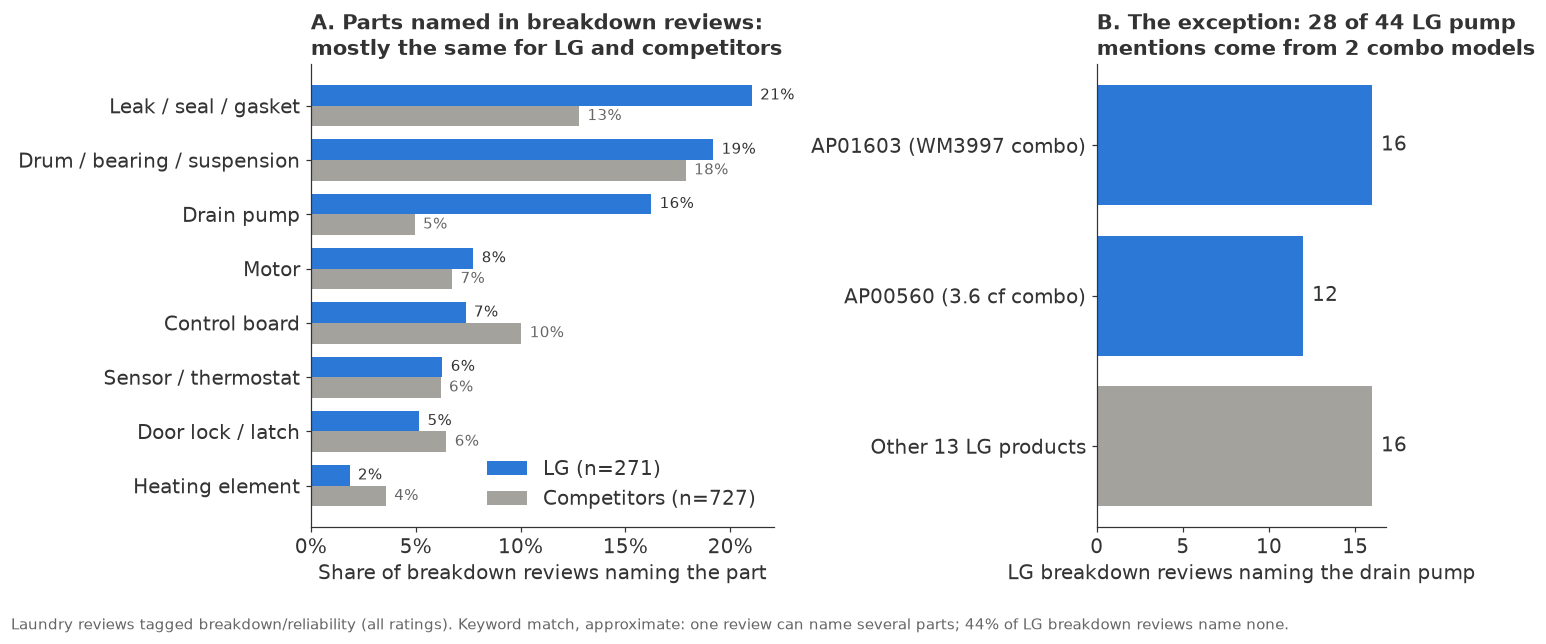

,LG,Competitors
Heating element,0.018,0.036
Door lock / latch,0.052,0.065
Sensor / thermostat,0.063,0.062
Control board,0.074,0.100
Motor,0.077,0.067
Drain pump,0.162,0.050
Drum / bearing / suspension,0.192,0.179
Leak / seal / gasket,0.210,0.128


In [12]:
d["t"] = d.text.str.lower()
rel = d[d.a_reliability == 1]; lgr, cor = rel[rel.is_lg == 1], rel[rel.is_lg == 0]
lg_all = d[d.is_lg == 1]

# (a) rate per LG model, models with >= 25 reviews
pp = lg_all.groupby("product_id").agg(n=("review_id", "size"), rate=("a_reliability", "mean"), title=("product_title", "first"))
big = pp[pp.n >= 25].sort_values("rate", ascending=False)
print(f"LG breakdown reviews: {len(lgr)} on {lgr.product_id.nunique()} products | LG average rate {lg_all.a_reliability.mean():.1%}")
print(f"(a) per-model rate, {len(big)} models with 25+ reviews: {big.rate.min():.0%}-{big.rate.max():.0%}")
# (b) top-3 products: share of breakdown mentions vs share of all LG reviews
top3 = lgr.product_id.value_counts().head(3)
print(f"(b) top-3 products hold {top3.sum()/len(lgr):.1%} of LG breakdown reviews and {lg_all.product_id.isin(top3.index).mean():.1%} of all LG reviews")

# (c) part words, LG vs competitors
PARTS = {
    "Drain pump": r"\bpump", "Leak / seal / gasket": r"\bleak|gasket|\bseal|flood",
    "Drum / bearing / suspension": r"\bbearings?\b|spider|\bdrum\b|suspension|shock|spring",
    "Control board": r"control board|main board|\bboard\b|\bpcb\b", "Motor": r"\bmotors?\b",
    "Door lock / latch": r"door lock|\block\b|latch|hinge", "Sensor / thermostat": r"sensor|thermistor|thermostat",
    "Heating element": r"heating element|\belement\b|heater"}
parts = pd.DataFrame({k: {"LG": lgr.t.str.contains(p).mean(), "Competitors": cor.t.str.contains(p).mean()} for k, p in PARTS.items()}).T.sort_values("LG")
no_part = ~lgr.t.str.contains("|".join(PARTS.values()))
print(f"(c) LG breakdown reviews naming no part: {no_part.mean():.0%}")
pump = lgr[lgr.t.str.contains(PARTS["Drain pump"])].product_id.value_counts()
print(f"Drain pump: {pump.head(2).sum()} of {pump.sum()} LG mentions from {pump.index[0]} and {pump.index[1]} (washer-dryer combos)")
assert set(pump.index[:2]) == {"AP01603", "AP00560"}   # if the tags change and this fails, reread the pump reviews

fig, (a, b2) = plt.subplots(1, 2, figsize=(13, 5.6), gridspec_kw={"width_ratios": [1.6, 1]})
y = np.arange(len(parts)); h = 0.38
a.barh(y + h/2, parts.LG, h, color=BLUE, label=f"LG (n={len(lgr)})")
a.barh(y - h/2, parts.Competitors, h, color=GREY, label=f"Competitors (n={len(cor)})")
for i, (l, c) in enumerate(zip(parts.LG, parts.Competitors)):
    a.text(l + .004, i + h/2, f"{l:.0%}", va="center", fontsize=10)
    a.text(c + .004, i - h/2, f"{c:.0%}", va="center", fontsize=10, color="#666666")
a.set_yticks(y); a.set_yticklabels(parts.index); a.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
a.set_xlabel("Share of breakdown reviews naming the part"); a.legend(loc="lower right")
a.set_title("A. Parts named in breakdown reviews:\nmostly the same for LG and competitors", fontsize=14)
conc = pd.Series({"AP01603 (WM3997 combo)": pump["AP01603"], "AP00560 (3.6 cf combo)": pump["AP00560"],
                  f"Other {pump.size - 2} LG products": pump.drop(["AP01603", "AP00560"]).sum()})
b2.barh(conc.index[::-1], conc.values[::-1], color=[GREY, BLUE, BLUE])
for i, v in enumerate(conc.values[::-1]): b2.text(v + .5, i, str(v), va="center")
b2.set_xlabel("LG breakdown reviews naming the drain pump")
b2.set_title(f"B. The exception: {pump.head(2).sum()} of {pump.sum()} LG pump\nmentions come from 2 combo models", fontsize=14)
note(fig, f"Laundry reviews tagged breakdown/reliability (all ratings). Keyword match, approximate: one review can name several parts; "
          f"{no_part.mean():.0%} of LG breakdown reviews name none.")
fig.tight_layout(); fig.savefig(FIG / "chart6_breakdown_parts.png"); plt.show()
parts.round(3)